In [129]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [130]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"
path_crop_out = path_processed / "od_images"

size_preview = (500, 500)

seed = 123

In [5]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT,Height,Width
str,i64,str,f64,str,i64,i64
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN""",1918,1918
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN""",1929,1929
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN""",1940,1940
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN""",1893,1893
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN""",1900,1900


# Tools

In [6]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [7]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [8]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [9]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

# Optic Dics (OD)

In [112]:
# Params
# img_file_name = "226_0"  # set to none for random
img_file_name = None

kernel_clean_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)) # remove random pixel
kernel_erode_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51)) # erode fov region to avoid halo
erode_iter = 10
fov_thres_val = 20

gaussian_blur_kernel: tuple = (71, 71)

crop_ratio = 0.3
crop_resize = 512

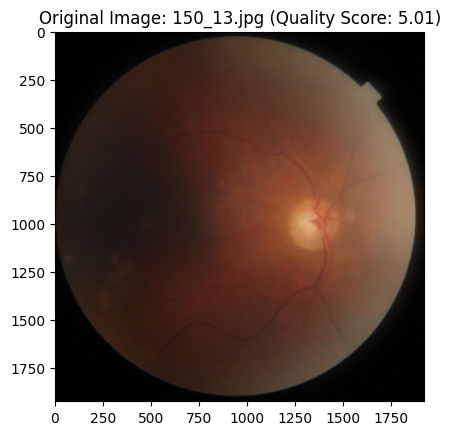

In [113]:
# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

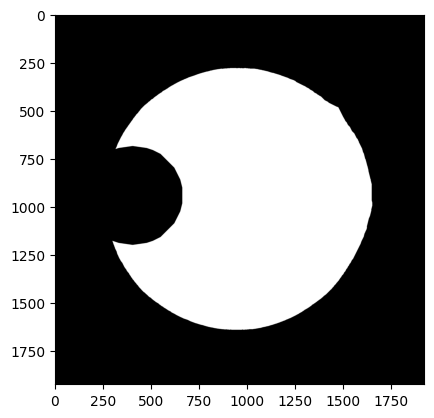

In [114]:
# get fov mask
img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
_, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

# clean fov mask
fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

plt.imshow(fov_mask, cmap="gray")

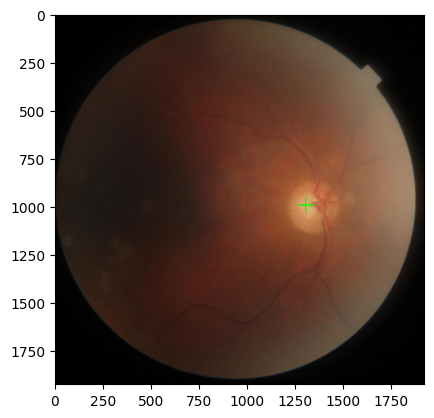

In [115]:
# find brightest spot
img_red = img_ori[:, :, 2]
img_blur = cv2.GaussianBlur(img_red, gaussian_blur_kernel, 0)
masked_img = cv2.bitwise_and(img_blur, img_blur, mask=fov_mask)
_, _, _, max_loc = cv2.minMaxLoc(masked_img)

# mark detected spot
out = cv2.drawMarker(img_ori.copy(), max_loc, (0, 255, 0), cv2.MARKER_CROSS, 80, 5)

# imshow(out)
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))

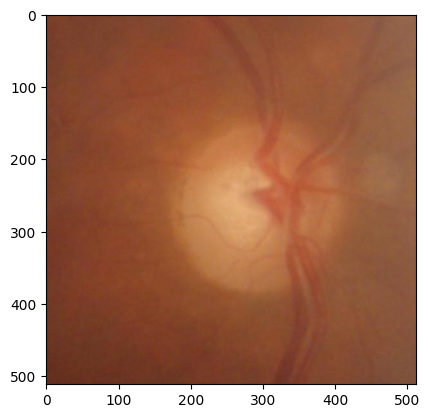

In [116]:
# cropping
crop_width = int(sample_width * crop_ratio)
crop_height = int(sample_height * crop_ratio)

x1 = max(max_loc[0] - crop_width // 2, 0)
y1 = max(max_loc[1] - crop_height // 2, 0)
x2 = min(max_loc[0] + crop_width // 2, sample_width)
y2 = min(max_loc[1] + crop_height // 2, sample_height)

cropped_img = img_ori[y1:y2, x1:x2]
cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))
plt.imshow(cv2.cvtColor(cropped_resize_img, cv2.COLOR_BGR2RGB))

# OD Batch crop

In [117]:
def crop_od(path: str):
    # load
    img_ori = cv2.imread(path)

    # params
    kernel_clean_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (15, 15)
    )  # remove random pixel
    kernel_erode_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (51, 51)
    )  # erode fov region to avoid halo
    erode_iter = 10
    fov_thres_val = 20
    gaussian_blur_kernel: tuple = (71, 71)
    crop_ratio = 0.3
    crop_resize = 512
    sample_height = img_ori.shape[0]
    sample_width = img_ori.shape[1]

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

    # find brightest spot
    img_red = img_ori[:, :, 2]
    img_blur = cv2.GaussianBlur(img_red, gaussian_blur_kernel, 0)
    masked_img = cv2.bitwise_and(img_blur, img_blur, mask=fov_mask)
    _, _, _, max_loc = cv2.minMaxLoc(masked_img)

    # cropping
    crop_width = int(sample_width * crop_ratio)
    crop_height = int(sample_height * crop_ratio)

    x1 = max(max_loc[0] - crop_width // 2, 0)
    y1 = max(max_loc[1] - crop_height // 2, 0)
    x2 = min(max_loc[0] + crop_width // 2, sample_width)
    y2 = min(max_loc[1] + crop_height // 2, sample_height)

    cropped_img = img_ori[y1:y2, x1:x2]
    cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

    return cropped_resize_img

In [ ]:
img_ls = df.select('Image Name').to_numpy().flatten().tolist()
os.mkdir(path_crop_out)

for i in img_ls:
    img_path = path_raw_img / i
    cropped_img = crop_od(img_path)
    save_path = path_crop_out / i
    cv2.imwrite(str(save_path), cropped_img)